In [14]:
import numpy as np
import os
import showerdata
import yaml

from tqdm.auto import tqdm
import torch
from allshowers import transformer, flow_matching, data_util
from torch.utils.data import Dataset, DataLoader
import h5py as h5

import matplotlib.pyplot as plt
import random

from torch import nn
from torch.nn.attention.flex_attention import (
    BlockMask,
    create_block_mask,
    create_mask,
    flex_attention,
)

import torch
from torch import nn
import triton
import triton.language as tl

In [15]:
from allshowers.indexer import Indexer

## Data loader busineess 

In [16]:
with open("./conf/transformer.yaml") as f:
    conf = yaml.safe_load(f)


device = "cuda:0"
RESIZE_FACTOR = 1
max_points = 6016
num_timesteps = 32
start_idx = 500_000
    
config_dataset = conf["data"].copy()
config_dataset["num_layers"] = conf["model"]["num_layers"]
trafos_file = "./trafos/trafos.pt"

(energy_scaler,
 coordinate_scaler,
 conditioning_scaler) = data_util.ShowerDatasetFromH5.PrepareScalesFromTrafoFile(config_dataset,
                                                                                 trafo_path=trafos_file,
                                                                                 rank = 0,
                                                                                 world_size=1,
                                                                                 local_rank=0)

transformed_dataset = data_util.ShowerDatasetFromH5(path = config_dataset["path"],
                                          energy_scaler=energy_scaler,
                                          coordinate_scaler=coordinate_scaler,
                                          conditioning_scaler = conditioning_scaler,
                                          start = start_idx,
                                          stop = start_idx + 100_000,
                                          num_layers=config_dataset["num_layers"]
                                         )

dataloader = DataLoader(transformed_dataset,
                        batch_size=32,
                        shuffle=False,
                        num_workers=16,
                        pin_memory=True,
                        persistent_workers=True)


In [17]:
batch = next(iter(dataloader))

In [18]:
condition = batch["cond"]
num_points = batch["num_points"]
label = batch["label"]
condition = condition.to(device)
label = label.to(device)
num_points = num_points.to(device)

In [19]:
model_config = conf["model"]
flow_config = model_config.pop("flow_config")
network = transformer.Transformer(**model_config)

## Masking Logic

In [20]:
layer = torch.zeros((condition.shape[0],
                     max_points, 1),
                    dtype=torch.int32,
                    device=device
                   )
mask = torch.zeros((condition.shape[0],
                    max_points, 1),
                   dtype=torch.bool,
                   device=device
                  )


for i in range(condition.shape[0]):
    total_points = torch.sum(num_points[i])
    layer_i = torch.repeat_interleave(num_points[i])
    if total_points > max_points:
        warnings.warn(
            f"num points {total_points} exceeds max points {self.max_points}, truncating"
        )
        total_points = self.max_points
        layer_i = layer_i[: self.max_points]
    layer[i, :total_points, 0] = layer_i
    mask[i, :total_points, 0] = True

## Indexer Bussiness

In [28]:
indexer = Indexer(
    hidden_dim = 64,
    head_dim = 16,
    n_heads = 4,
    TOP_K=64
)
indexer = indexer.to(device)


In [29]:
indexer = torch.compile(indexer)

In [30]:
z = torch.randn(32,
                6016,
                64,
                device=device
               )

indexer.eval()

OptimizedModule(
  (_orig_mod): Indexer(
    (Wq): Linear(in_features=64, out_features=64, bias=True)
    (Wk): Linear(in_features=64, out_features=16, bias=True)
    (Ww): Linear(in_features=64, out_features=4, bias=True)
  )
)

In [31]:
top_mask, n_maks = indexer(z,mask,layer)

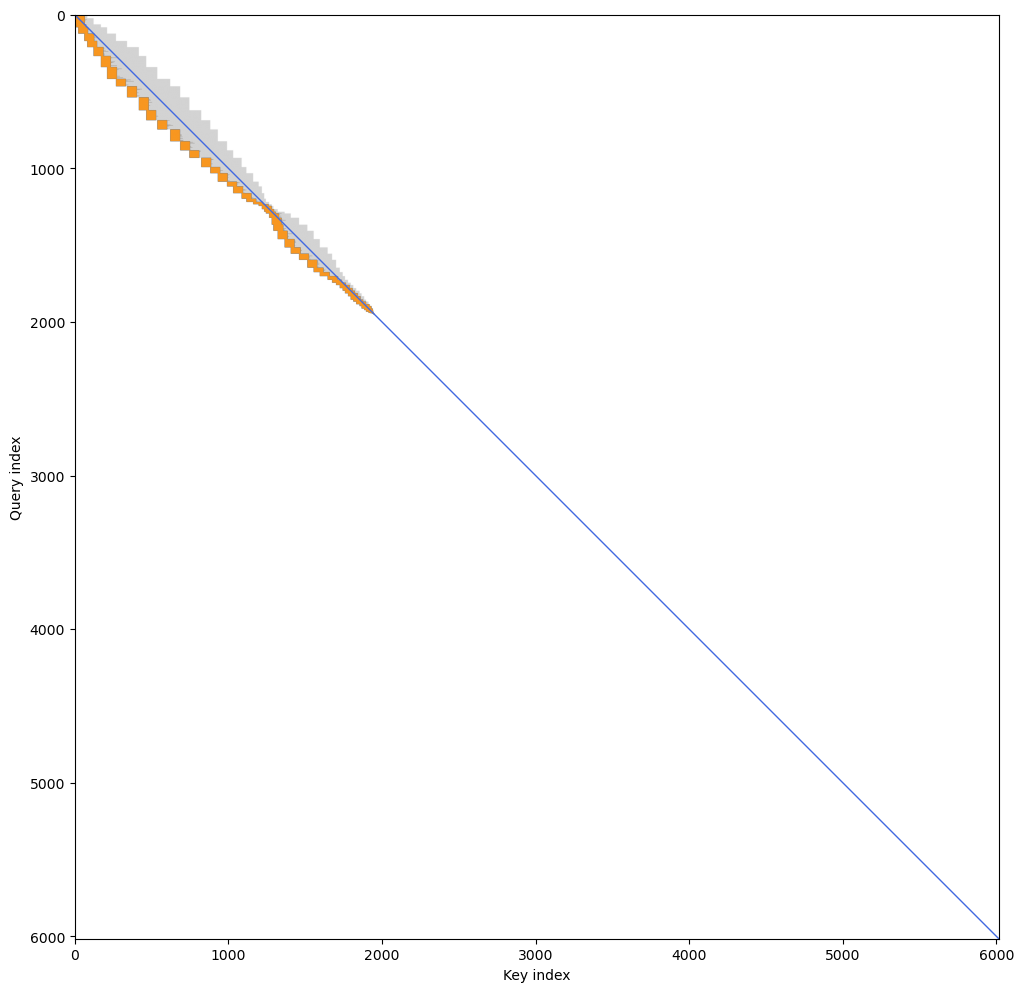

In [33]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

fig, ax = plt.subplots(figsize=(12, 12))

element = 7

base = n_mask[element].detach().cpu().numpy()
top = top_mask[element].detach().cpu().numpy()

ax.imshow(
    base,
    cmap=ListedColormap(["white", "lightgray"]),
    vmin=0, vmax=1,
)
ax.imshow(
    np.ma.masked_where(top == 0, top),
    cmap=ListedColormap(["darkorange"]),
    vmin=0, vmax=1,
    alpha=0.85,
)

n = min(base.shape)
ax.plot([0, n - 1], [0, n - 1], color="royalblue", linewidth=1)

ax.set_xlabel("Key index")
ax.set_ylabel("Query index")
plt.show()

In [12]:


b_idx = INDEXER.get_begin_idx(b)
q_idx = INDEXER.get_begin_idx(q)

b_new = []
q_new = []
v_new = []

start_idx = []
stop_idx = []
for i in tqdm(range(0,len(q_idx))):

    start = q_idx[i]
    
    if i == len(q_idx)-1:
        stop = len(q)
    else:
        stop = q_idx[i+1]
    
    start_idx.append(start)
    stop_idx.append(stop)
    
start_idx = torch.tensor(start_idx,device=device)
stop_idx = torch.tensor(stop_idx,device=device)


100%|██████████| 67057/67057 [00:00<00:00, 98105.21it/s] 


In [11]:
output = torch.full_like(v,-1)

In [12]:
grid = (len(start_idx),)

In [13]:
t_kernel = INDEXER.padded_topk[grid](
    v,
    scores,
    output,
    start_idx,
    stop_idx,
    TOP_K=4,
    BLOCK_SIZE=1024,
)

In [14]:
mask = output !=-1
b_new,q_new,v_new = b[mask],q[mask],v[mask]
index_vec = torch.concatenate([b_new[:,None],q_new[:,None],v_new[:,None]],-1)

In [37]:
## Mask as a dimension of m,3 where 3--> B,Q,V
## output ptr ---> B,L.L


@triton.jit
def triton_custom_mask(
    mask_stream_ptr,
    output_ptr,
    n_elements: tl.constexpr,
    BLOCK_SIZE: tl.constexpr, ## Number of streams to process
    SEQUENCE_LENGTH: tl.constexpr,
    BATCH_SIZE: tl.constexpr
):

    pid = tl.program_id(axis=0)

    begin_idx = BLOCK_SIZE*pid
    
    indices = pid * BLOCK_SIZE + tl.arange(0, BLOCK_SIZE)
    valid = indices < n_elements
    
    

    b = tl.load(
        mask_stream_ptr + indices * 3,
        mask=valid,
        other=0,
    )
    
    q = tl.load(
        mask_stream_ptr + indices * 3 + 1,
        mask=valid,
        other=0,
    )
    
    v = tl.load(
        mask_stream_ptr + indices * 3 + 2,
        mask=valid,
        other=0,
    )

    output_indices = (b.to(tl.int64) * SEQUENCE_LENGTH**2
    + q.to(tl.int64) * SEQUENCE_LENGTH
    + v.to(tl.int64))

    tl.store(
    output_ptr + output_indices,
    1,
    mask=valid,)
    
    

In [38]:
all_mask = torch.empty((z.shape[0],z.shape[1],z.shape[1]),dtype=torch.bool,device=device)
all_mask[...] = False

BLOCK_SIZE = 8192
grid = (triton.cdiv(len(index_vec), BLOCK_SIZE),)
t_kernel = triton_custom_mask[grid](
    mask_stream_ptr= index_vec,
    output_ptr = all_mask,
    n_elements =  len(index_vec),
    BLOCK_SIZE =  BLOCK_SIZE, ## Number of streams to process
    SEQUENCE_LENGTH = z.shape[1],
    BATCH_SIZE =  z.shape[0]
)


In [42]:
all_mask

tensor([[[ True,  True,  True,  ..., False, False, False],
         [ True,  True,  True,  ..., False, False, False],
         [ True,  True,  True,  ..., False, False, False],
         ...,
         [False, False, False,  ..., False, False, False],
         [False, False, False,  ..., False, False, False],
         [False, False, False,  ..., False, False, False]],

        [[ True, False, False,  ..., False, False, False],
         [False,  True, False,  ..., False, False, False],
         [False, False,  True,  ..., False, False, False],
         ...,
         [False, False, False,  ..., False, False, False],
         [False, False, False,  ..., False, False, False],
         [False, False, False,  ..., False, False, False]],

        [[ True,  True,  True,  ..., False, False, False],
         [ True,  True,  True,  ..., False, False, False],
         [ True,  True,  True,  ..., False, False, False],
         ...,
         [False, False, False,  ..., False, False, False],
         [

In [18]:
def mask_fn(b, h, q_idx, kv_idx):
    return all_mask[b,q_idx,kv_idx]

block_mask = create_block_mask(
    mask_mod=mask_fn,
    B=16,
    H=None,
    Q_LEN=6016,
    KV_LEN=6016,
    device=str(device),
)

In [19]:
vis_mask = create_mask(
    mask_fn,
    B=16,
    H=None,
    Q_LEN=6016,
    KV_LEN=6016,
    device=device,
)

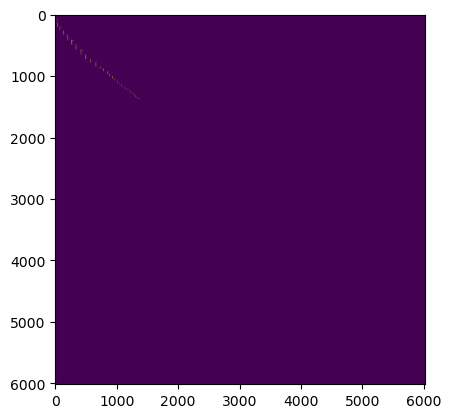

In [20]:
plt.imshow(vis_mask[2,0,:,:].cpu())

In [21]:
vis_mask.shape

torch.Size([16, 1, 6016, 6016])

In [22]:
block_mask

BlockMask(
    kv_num_blocks=torch.Size([16, 1, 47]),
    kv_indices=torch.Size([16, 1, 47, 47]),
    full_kv_num_blocks=torch.Size([16, 1, 47]),
    full_kv_indices=torch.Size([16, 1, 47, 47]),
    q_num_blocks=torch.Size([16, 1, 47]),
    q_indices=torch.Size([16, 1, 47, 47]),
    full_q_num_blocks=torch.Size([16, 1, 47]),
    full_q_indices=torch.Size([16, 1, 47, 47]),
    BLOCK_SIZE=(128, 128),
    shape=(16, 1, 6016, 6016),
    sparsity=98.28%,
    mask_mod=mask_fn
)

In [23]:
mask.shape

torch.Size([20256197])

In [24]:
import triton
import triton.language as tl

In [25]:
## The truth mask is B,Q,K or B,L,L
## On kernel attends to [B_i,Q_i,L]
## layer of size [B,L]
## mask of size [B,L]

@triton.jit
def triton_mask_maker(
    layer_ptr,
    mask_ptr,
    output_ptr,
    NUM_LAYER_COND: tl.constexpr,
    SEQUENCE_LENGTH: tl.constexpr,
    BATCH_SIZE: tl.constexpr
):


    BLOCK_SIZE: tl.constexpr = 8192 ## This has to be changed according to the number of point clouds
    
    pid_batch = tl.program_id(axis=0).to(tl.int64)
    pid_query = tl.program_id(axis=1).to(tl.int64)

    key_indices = tl.arange(0, BLOCK_SIZE)

    layer_ = tl.load(layer_ptr +
                     pid_batch*SEQUENCE_LENGTH +
                     key_indices,
                     mask = key_indices < SEQUENCE_LENGTH,
                     other = -1)

    query_layer = tl.load(layer_ptr + 
                          pid_batch * SEQUENCE_LENGTH + 
                          pid_query)

    mask_ =  tl.load(mask_ptr +
                     pid_batch*SEQUENCE_LENGTH +
                     key_indices,
                     mask = key_indices < SEQUENCE_LENGTH,
                     other = 0)
    
    query_mask = tl.load(mask_ptr + 
                          pid_batch * SEQUENCE_LENGTH + 
                          pid_query)

    lower_bound = query_layer - layer_ >= -((NUM_LAYER_COND + 1) // 2)
    upper_bound = query_layer - layer_ <=  ((NUM_LAYER_COND // 2))

    not_padding = query_mask & mask_


    valid_mask = lower_bound & upper_bound & not_padding & (key_indices < SEQUENCE_LENGTH)

    tl.store(
    output_ptr
    + pid_batch * SEQUENCE_LENGTH * SEQUENCE_LENGTH
    + pid_query * SEQUENCE_LENGTH
    + key_indices,
    valid_mask,
    mask=key_indices < SEQUENCE_LENGTH,)
    

In [26]:
layer = torch.zeros((condition.shape[0],
                     max_points, 1),
                    dtype=torch.int32,
                    device=device
                   )
mask = torch.zeros((condition.shape[0],
                    max_points, 1),
                   dtype=torch.bool,
                   device=device
                  )


for i in range(condition.shape[0]):
    total_points = torch.sum(num_points[i])
    layer_i = torch.repeat_interleave(num_points[i])
    if total_points > max_points:
        warnings.warn(
            f"num points {total_points} exceeds max points {self.max_points}, truncating"
        )
        total_points = self.max_points
        layer_i = layer_i[: self.max_points]
    layer[i, :total_points, 0] = layer_i
    mask[i, :total_points, 0] = True

In [27]:
layer = layer[:,:,0]
mask = mask[:,:,0]
all_mask = torch.empty((condition.shape[0], max_points,max_points),dtype=torch.bool,device=device)
grid = (all_mask.shape[0],all_mask.shape[1])

In [30]:
grid

(256, 6016)

In [31]:
t_kernel = triton_mask_maker[grid](
    layer_ptr = layer,
    mask_ptr = mask,
    output_ptr = all_mask,
    NUM_LAYER_COND = 4,
    SEQUENCE_LENGTH =  mask.shape[1],
    BATCH_SIZE =  mask.shape[0]
)

In [33]:
B, L = layer.shape

print("Layer:", layer.shape, layer.stride())
print("Mask:", mask.shape, mask.stride())
print("Output:", all_mask.shape, all_mask.stride())
print("Grid:", grid)

assert layer.shape == (B, L)
assert mask.shape == (B, L)
assert all_mask.shape == (B, L, L)

assert layer.is_contiguous()
assert mask.is_contiguous()
assert all_mask.is_contiguous()

assert layer.device == mask.device == all_mask.device
assert L <= 8192
assert grid == (B, L)

Layer: torch.Size([256, 6016]) (6016, 1)
Mask: torch.Size([256, 6016]) (6016, 1)
Output: torch.Size([256, 6016, 6016]) (36192256, 6016, 1)
Grid: (256, 6016)


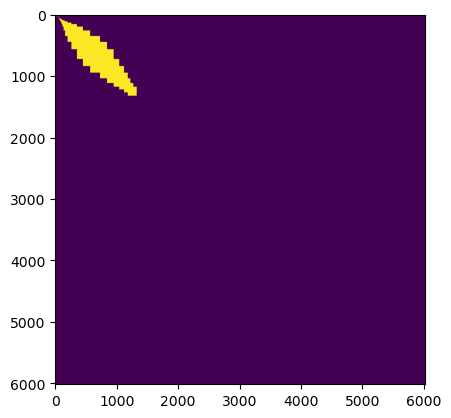

In [33]:
plt.imshow(all_mask[0,:,:].cpu())